# 06 - Hyperparameter Tuning and Model Evaluation

## Predicting Credit Card Fraud

### Objectives

- Apply Stratified K-Fold Cross Validation.
- Optimize LightGBM and XGBoost.
- Use RandomizedSearchCV.
- Compare tuned and baseline models.
- Optimize classification thresholds.
- Evaluate Precision, Recall and F1-Score.
- Select the final model.

### Experimental setup

- Feature set: Engineered Features.
- Sampling strategy: Random Oversampling.
- Sampling ratio: 0.1.
- Cross-validation: Stratified 3-Fold.
- Hyperparameter optimization: RandomizedSearchCV.
- Primary optimization metric: Average Precision.
- Secondary metric: ROC-AUC.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import time

from pathlib import Path

from sklearn.base import clone

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_validate
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
    confusion_matrix
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 5)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.5f}")

In [2]:
possible_paths = [
    Path.cwd() / "data" / "raw",
    Path.cwd().parent / "data" / "raw"
]

DATA_DIR = next(
    (path for path in possible_paths if path.exists()),
    None
)

if DATA_DIR is None:
    raise FileNotFoundError("Could not locate data/raw directory")

train = pd.read_csv(DATA_DIR / "train.csv")

print("Train shape:", train.shape)

Train shape: (699960, 26)


In [3]:
TARGET = "is_fraud"
ID_COL = "id"

X = train.drop(
    columns=[TARGET, ID_COL]
).copy()

y = train[TARGET].astype("int8").copy()

print("X:", X.shape)
print("y:", y.shape)

print("\nTarget distribution:")
display(y.value_counts(normalize=True) * 100)

X: (699960, 24)
y: (699960,)

Target distribution:


is_fraud
0   98.33005
1    1.66995
Name: proportion, dtype: float64

In [4]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)

print("\nTrain fraud rate:", y_train.mean() * 100)
print("Validation fraud rate:", y_valid.mean() * 100)

X_train: (559968, 24)
X_valid: (139992, 24)

Train fraud rate: 1.669916852391565
Validation fraud rate: 1.6700954340248013


In [5]:
def engineer_features(df):

    df = df.copy()

    # Ratios
    df["amount_to_abs_balance_ratio"] = (
        df["amount_usd"] /
        (df["account_balance_usd"].abs() + 1)
    )

    df["cvv_retries_per_recent_txn"] = (
        df["cvv_retry_count"] /
        (df["txn_count_last_24h"] + 1)
    )

    # Risk interactions
    df["vpn_ip_mismatch"] = (
        df["used_vpn"] &
        df["ip_country_mismatch"]
    )

    df["foreign_ip_mismatch"] = (
        df["is_foreign_transaction"] &
        df["ip_country_mismatch"]
    )

    df["foreign_billing_mismatch"] = (
        df["is_foreign_transaction"] &
        df["billing_shipping_mismatch"]
    )

    security_flags = [
        "is_foreign_transaction",
        "is_new_merchant",
        "used_vpn",
        "ip_country_mismatch",
        "billing_shipping_mismatch"
    ]

    df["security_risk_flags_count"] = (
        df[security_flags]
        .astype("int8")
        .sum(axis=1)
        .astype("int8")
    )

    # Numerical interactions
    df["merchant_velocity_interaction"] = (
        df["merchant_risk_score"] *
        df["velocity_score"]
    )

    df["cvv_velocity_interaction"] = (
        df["cvv_retry_count"] *
        df["velocity_score"]
    )

    # Logarithmic transformations
    log_features = [
        "amount_usd",
        "account_balance_usd",
        "cvv_retry_count",
        "prior_disputes"
    ]

    for col in log_features:

        df[f"log_{col}"] = (
            np.sign(df[col]) *
            np.log1p(np.abs(df[col]))
        )

    # Cyclical encoding
    hour = df["time_of_day_hour"] % 24
    day = df["day_of_week"] % 7

    df["hour_sin"] = np.sin(
        2 * np.pi * hour / 24
    )

    df["hour_cos"] = np.cos(
        2 * np.pi * hour / 24
    )

    df["day_sin"] = np.sin(
        2 * np.pi * day / 7
    )

    df["day_cos"] = np.cos(
        2 * np.pi * day / 7
    )

    return df

In [6]:
X_train_fe = engineer_features(X_train)

X_valid_fe = engineer_features(X_valid)

print("Original features:", X_train.shape[1])

print("Engineered training:", X_train_fe.shape)

print("Engineered validation:", X_valid_fe.shape)

Original features: 24
Engineered training: (559968, 40)
Engineered validation: (139992, 40)


In [7]:
X_dev, X_threshold, y_dev, y_threshold = train_test_split(
    X_train_fe,
    y_train,
    test_size=0.20,
    random_state=2026,
    stratify=y_train
)

print("Development set:", X_dev.shape)
print("Threshold selection set:", X_threshold.shape)

print("\nDevelopment fraud rate:", y_dev.mean() * 100)
print("Threshold fraud rate:", y_threshold.mean() * 100)

Development set: (447974, 40)
Threshold selection set: (111994, 40)

Development fraud rate: 1.6699629889234644
Threshold fraud rate: 1.6697323070878796


In [8]:
boolean_cols = [
    col for col in X_dev.columns
    if pd.api.types.is_bool_dtype(X_dev[col])
]

categorical_cols = [
    col for col in X_dev.columns
    if (
        pd.api.types.is_object_dtype(X_dev[col])
        or pd.api.types.is_string_dtype(X_dev[col])
    )
]

numeric_cols = [
    col for col in X_dev.columns
    if (
        pd.api.types.is_numeric_dtype(X_dev[col])
        and not pd.api.types.is_bool_dtype(X_dev[col])
    )
]

print("Numerical:", len(numeric_cols))
print("Categorical:", len(categorical_cols))
print("Boolean:", len(boolean_cols))
print("Total:", len(numeric_cols) + len(categorical_cols) + len(boolean_cols))

assert len(numeric_cols) + len(categorical_cols) + len(boolean_cols) == 40

Numerical: 26
Categorical: 5
Boolean: 9
Total: 40


In [9]:
def create_tree_preprocessor(df):

    bool_cols = [
        col for col in df.columns
        if pd.api.types.is_bool_dtype(df[col])
    ]

    cat_cols = [
        col for col in df.columns
        if (
            pd.api.types.is_object_dtype(df[col])
            or pd.api.types.is_string_dtype(df[col])
        )
    ]

    num_cols = [
        col for col in df.columns
        if (
            pd.api.types.is_numeric_dtype(df[col])
            and not pd.api.types.is_bool_dtype(df[col])
        )
    ]

    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False,
        dtype=np.float32
    )

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", "passthrough", num_cols),
            ("cat", encoder, cat_cols),
            ("bool", "passthrough", bool_cols)
        ],
        remainder="drop"
    )

    return preprocessor

In [10]:
def create_lightgbm():

    return LGBMClassifier(
        objective="binary",
        n_estimators=200,
        learning_rate=0.1,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=20,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        n_jobs=-1,
        random_state=42,
        verbosity=-1
    )


def create_xgboost():

    return XGBClassifier(
        objective="binary:logistic",
        eval_metric="auc",
        n_estimators=200,
        learning_rate=0.1,
        max_depth=6,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        tree_method="hist",
        n_jobs=-1,
        random_state=42,
        verbosity=0
    )


# Build complete pipeline
def create_pipeline(estimator, X_reference):

    return Pipeline(
        steps=[
            (
                "sampler",
                RandomOverSampler(
                    sampling_strategy=0.1,
                    random_state=42
                )
            ),
            (
                "preprocessing",
                create_tree_preprocessor(X_reference)
            ),
            (
                "classifier",
                estimator
            )
        ]
    )


initial_models = {
    "LightGBM": create_lightgbm(),
    "XGBoost": create_xgboost()
}

In [11]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

SCORING = {
    "average_precision": "average_precision",
    "roc_auc": "roc_auc"
}

print("Cross-validation configured.")
print("Number of folds:", cv.get_n_splits())

Cross-validation configured.
Number of folds: 3


In [12]:
baseline_cv_results = []

for model_name, estimator in initial_models.items():

    print(f"\nEvaluating {model_name}")

    pipeline = create_pipeline(
        estimator,
        X_dev
    )

    start_time = time.perf_counter()

    scores = cross_validate(
        pipeline,
        X_dev,
        y_dev,
        cv=cv,
        scoring=SCORING,
        n_jobs=1,
        return_train_score=False
    )

    elapsed_time = time.perf_counter() - start_time

    baseline_cv_results.append({

        "model": model_name,

        "mean_average_precision": (
            scores["test_average_precision"].mean()
        ),

        "std_average_precision": (
            scores["test_average_precision"].std()
        ),

        "mean_roc_auc": (
            scores["test_roc_auc"].mean()
        ),

        "std_roc_auc": (
            scores["test_roc_auc"].std()
        ),

        "total_time_seconds": elapsed_time
    })

    print(
        "Average Precision:",
        f"{scores['test_average_precision'].mean():.5f}"
    )

    print(
        "ROC-AUC:",
        f"{scores['test_roc_auc'].mean():.5f}"
    )

    print(f"Time: {elapsed_time:.2f} seconds")


baseline_cv_df = pd.DataFrame(
    baseline_cv_results
).set_index("model")

display(baseline_cv_df)


Evaluating LightGBM
Average Precision: 0.49043
ROC-AUC: 0.94380
Time: 7.58 seconds

Evaluating XGBoost
Average Precision: 0.48336
ROC-AUC: 0.94284
Time: 10.33 seconds


,mean_average_precision,std_average_precision,mean_roc_auc,std_roc_auc,total_time_seconds
model,,,,,
LightGBM,0.49043,0.01167,0.94380,0.00106,7.57841
XGBoost,0.48336,0.00956,0.94284,0.00160,10.32651


In [13]:
param_spaces = {

    "LightGBM": {

        "classifier__n_estimators": [
            200, 300, 400, 500
        ],

        "classifier__learning_rate": [
            0.02, 0.03, 0.05, 0.07, 0.1
        ],

        "classifier__num_leaves": [
            15, 31, 47, 63
        ],

        "classifier__max_depth": [
            -1, 8, 12, 16
        ],

        "classifier__min_child_samples": [
            20, 40, 60, 100
        ],

        "classifier__subsample": [
            0.7, 0.8, 0.9, 1.0
        ],

        "classifier__colsample_bytree": [
            0.7, 0.8, 0.9, 1.0
        ],

        "classifier__reg_lambda": [
            0, 1, 3, 5, 10
        ]

    },

    "XGBoost": {

        "classifier__n_estimators": [
            200, 300, 400, 500
        ],

        "classifier__learning_rate": [
            0.02, 0.03, 0.05, 0.07, 0.1
        ],

        "classifier__max_depth": [
            3, 4, 5, 6, 8
        ],

        "classifier__min_child_weight": [
            1, 3, 5, 8
        ],

        "classifier__subsample": [
            0.7, 0.8, 0.9, 1.0
        ],

        "classifier__colsample_bytree": [
            0.7, 0.8, 0.9, 1.0
        ],

        "classifier__reg_lambda": [
            0.5, 1, 3, 5, 10
        ],

        "classifier__gamma": [
            0, 0.1, 0.3, 0.5
        ]

    }

}

print("Search spaces configured.")

Search spaces configured.


In [14]:
searches = {}
search_results = []

N_ITER = 8

for model_name, estimator in initial_models.items():

    print("\n" + "=" * 65)
    print("TUNING:", model_name)
    print("=" * 65)

    pipeline = create_pipeline(
        estimator,
        X_dev
    )

    search = RandomizedSearchCV(

        estimator=pipeline,

        param_distributions=param_spaces[model_name],

        n_iter=N_ITER,

        scoring=SCORING,

        refit="average_precision",

        cv=cv,

        n_jobs=1,

        random_state=42,

        verbose=1,

        pre_dispatch=1,

        error_score="raise",

        return_train_score=False
    )

    start_time = time.perf_counter()

    search.fit(X_dev, y_dev)

    elapsed_time = time.perf_counter() - start_time

    searches[model_name] = search

    best_index = search.best_index_

    search_results.append({

        "model": model_name,

        "best_cv_average_precision": search.best_score_,

        "cv_std_average_precision": (
            search.cv_results_[
                "std_test_average_precision"
            ][best_index]
        ),

        "best_cv_roc_auc": (
            search.cv_results_[
                "mean_test_roc_auc"
            ][best_index]
        ),

        "search_time_seconds": elapsed_time,

        "best_params": search.best_params_

    })

    print("\nBest Average Precision:", f"{search.best_score_:.5f}")

    print("\nBest parameters:")

    print(search.best_params_)

    print(f"\nTotal time: {elapsed_time:.2f} seconds")


TUNING: LightGBM
Fitting 3 folds for each of 8 candidates, totalling 24 fits

Best Average Precision: 0.49588

Best parameters:
{'classifier__subsample': 0.8, 'classifier__reg_lambda': 1, 'classifier__num_leaves': 31, 'classifier__n_estimators': 400, 'classifier__min_child_samples': 100, 'classifier__max_depth': -1, 'classifier__learning_rate': 0.03, 'classifier__colsample_bytree': 0.7}

Total time: 86.31 seconds

TUNING: XGBoost
Fitting 3 folds for each of 8 candidates, totalling 24 fits

Best Average Precision: 0.49813

Best parameters:
{'classifier__subsample': 0.7, 'classifier__reg_lambda': 0.5, 'classifier__n_estimators': 300, 'classifier__min_child_weight': 1, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.07, 'classifier__gamma': 0.1, 'classifier__colsample_bytree': 0.9}

Total time: 96.08 seconds


In [15]:
tuning_df = pd.DataFrame(
    search_results
).set_index("model")

display(
    tuning_df.drop(
        columns=["best_params"]
    )
)

,best_cv_average_precision,cv_std_average_precision,best_cv_roc_auc,search_time_seconds
model,,,,
LightGBM,0.49588,0.00998,0.94517,86.30897
XGBoost,0.49813,0.01087,0.94586,96.08074


In [16]:
for model_name, search in searches.items():

    print("\n" + "=" * 55)

    print(model_name)

    print("=" * 55)

    for param, value in search.best_params_.items():

        print(f"{param}: {value}")


LightGBM
classifier__subsample: 0.8
classifier__reg_lambda: 1
classifier__num_leaves: 31
classifier__n_estimators: 400
classifier__min_child_samples: 100
classifier__max_depth: -1
classifier__learning_rate: 0.03
classifier__colsample_bytree: 0.7

XGBoost
classifier__subsample: 0.7
classifier__reg_lambda: 0.5
classifier__n_estimators: 300
classifier__min_child_weight: 1
classifier__max_depth: 3
classifier__learning_rate: 0.07
classifier__gamma: 0.1
classifier__colsample_bytree: 0.9


In [17]:
cv_comparison = pd.DataFrame({

    "Baseline_CV_AP": baseline_cv_df[
        "mean_average_precision"
    ],

    "Baseline_CV_ROC_AUC": baseline_cv_df[
        "mean_roc_auc"
    ],

    "Tuned_CV_AP": tuning_df[
        "best_cv_average_precision"
    ],

    "Tuned_CV_ROC_AUC": tuning_df[
        "best_cv_roc_auc"
    ]

})

cv_comparison["AP_improvement"] = (
    cv_comparison["Tuned_CV_AP"] -
    cv_comparison["Baseline_CV_AP"]
)

display(cv_comparison)

,Baseline_CV_AP,Baseline_CV_ROC_AUC,Tuned_CV_AP,Tuned_CV_ROC_AUC,AP_improvement
model,,,,,
LightGBM,0.49043,0.94380,0.49588,0.94517,0.00545
XGBoost,0.48336,0.94284,0.49813,0.94586,0.01477


In [18]:
threshold_results = []

thresholds_by_model = {}

for model_name, search in searches.items():

    print("\nEvaluating threshold selection:", model_name)

    model = search.best_estimator_

    # Predictions on independent threshold set
    y_proba = model.predict_proba(
        X_threshold
    )[:, 1]

    # Precision-Recall curve
    precision_values, recall_values, thresholds = (
        precision_recall_curve(
            y_threshold,
            y_proba
        )
    )

    # Precision and Recall aligned with thresholds
    precision_values = precision_values[:-1]
    recall_values = recall_values[:-1]

    # F1
    f1_values = (
        2 * precision_values * recall_values
    ) / (
        precision_values + recall_values + 1e-12
    )

    # F2: recall receives greater weight
    f2_values = (
        5 * precision_values * recall_values
    ) / (
        4 * precision_values + recall_values + 1e-12
    )

    # Best thresholds
    best_f1_idx = np.argmax(f1_values)

    best_f2_idx = np.argmax(f2_values)

    best_f1_threshold = thresholds[best_f1_idx]

    best_f2_threshold = thresholds[best_f2_idx]

    thresholds_by_model[model_name] = {

        "max_f1": best_f1_threshold,

        "max_f2": best_f2_threshold

    }

    threshold_results.append({

        "model": model_name,

        "best_f1_threshold": best_f1_threshold,

        "best_f1": f1_values[best_f1_idx],

        "precision_at_max_f1": precision_values[best_f1_idx],

        "recall_at_max_f1": recall_values[best_f1_idx],

        "best_f2_threshold": best_f2_threshold,

        "best_f2": f2_values[best_f2_idx],

        "precision_at_max_f2": precision_values[best_f2_idx],

        "recall_at_max_f2": recall_values[best_f2_idx]

    })

    print(f"Best F1 threshold: {best_f1_threshold:.5f}")

    print(f"Best F2 threshold: {best_f2_threshold:.5f}")


Evaluating threshold selection: LightGBM
Best F1 threshold: 0.65282
Best F2 threshold: 0.37407

Evaluating threshold selection: XGBoost
Best F1 threshold: 0.68003
Best F2 threshold: 0.39327


In [19]:
threshold_df = pd.DataFrame(
    threshold_results
).set_index("model")

display(threshold_df)

,best_f1_threshold,best_f1,precision_at_max_f1,recall_at_max_f1,best_f2_threshold,best_f2,precision_at_max_f2,recall_at_max_f2
model,,,,,,,,
LightGBM,0.65282,0.48934,0.53063,0.45401,0.37407,0.52636,0.31537,0.63209
XGBoost,0.68003,0.48865,0.56315,0.43155,0.39327,0.53010,0.32729,0.62727


In [20]:
validation_results = []

tuned_models = {}

validation_probabilities = {}

for model_name, search in searches.items():

    print("\nEvaluating final model:", model_name)

    # Best model fitted on X_dev
    model = search.best_estimator_

    tuned_models[model_name] = model

    # Validation probabilities
    y_proba = model.predict_proba(
        X_valid_fe
    )[:, 1]

    validation_probabilities[model_name] = y_proba

    # Thresholds
    threshold_options = {

        "Default 0.50": 0.5,

        "Max F1": thresholds_by_model[
            model_name
        ]["max_f1"],

        "Max F2": thresholds_by_model[
            model_name
        ]["max_f2"]

    }

    for threshold_name, threshold in threshold_options.items():

        y_pred = (
            y_proba >= threshold
        ).astype("int8")

        tn, fp, fn, tp = confusion_matrix(
            y_valid,
            y_pred,
            labels=[0, 1]
        ).ravel()

        validation_results.append({

            "model": model_name,

            "threshold_type": threshold_name,

            "threshold": threshold,

            "roc_auc": roc_auc_score(
                y_valid,
                y_proba
            ),

            "average_precision": average_precision_score(
                y_valid,
                y_proba
            ),

            "accuracy": accuracy_score(
                y_valid,
                y_pred
            ),

            "precision": precision_score(
                y_valid,
                y_pred,
                zero_division=0
            ),

            "recall": recall_score(
                y_valid,
                y_pred,
                zero_division=0
            ),

            "f1_score": f1_score(
                y_valid,
                y_pred,
                zero_division=0
            ),

            "true_positives": tp,

            "false_positives": fp,

            "false_negatives": fn,

            "true_negatives": tn,

            "predicted_frauds": int(y_pred.sum())

        })

validation_df = pd.DataFrame(
    validation_results
)

display(validation_df)


Evaluating final model: LightGBM

Evaluating final model: XGBoost


,model,threshold_type,threshold,roc_auc,average_precision,accuracy,precision,recall,f1_score,true_positives,false_positives,false_negatives,true_negatives,predicted_frauds
0,LightGBM,Default 0.50,0.50000,0.94365,0.50669,0.97908,0.40745,0.55646,0.47044,1301,1892,1037,135762,3193
1,LightGBM,Max F1,0.65282,0.94365,0.50669,0.98459,0.54648,0.45509,0.49662,1064,883,1274,136771,1947
2,LightGBM,Max F2,0.37407,0.94365,0.50669,0.97056,0.30989,0.62190,0.41366,1454,3238,884,134416,4692
3,XGBoost,Default 0.50,0.50000,0.94347,0.50856,0.97912,0.40805,0.55518,0.47038,1298,1883,1040,135771,3181
4,XGBoost,Max F1,0.68003,0.94347,0.50856,0.98530,0.58046,0.43199,0.49534,1010,730,1328,136924,1740
5,XGBoost,Max F2,0.39327,0.94347,0.50856,0.97233,0.32695,0.62062,0.42828,1451,2987,887,134667,4438


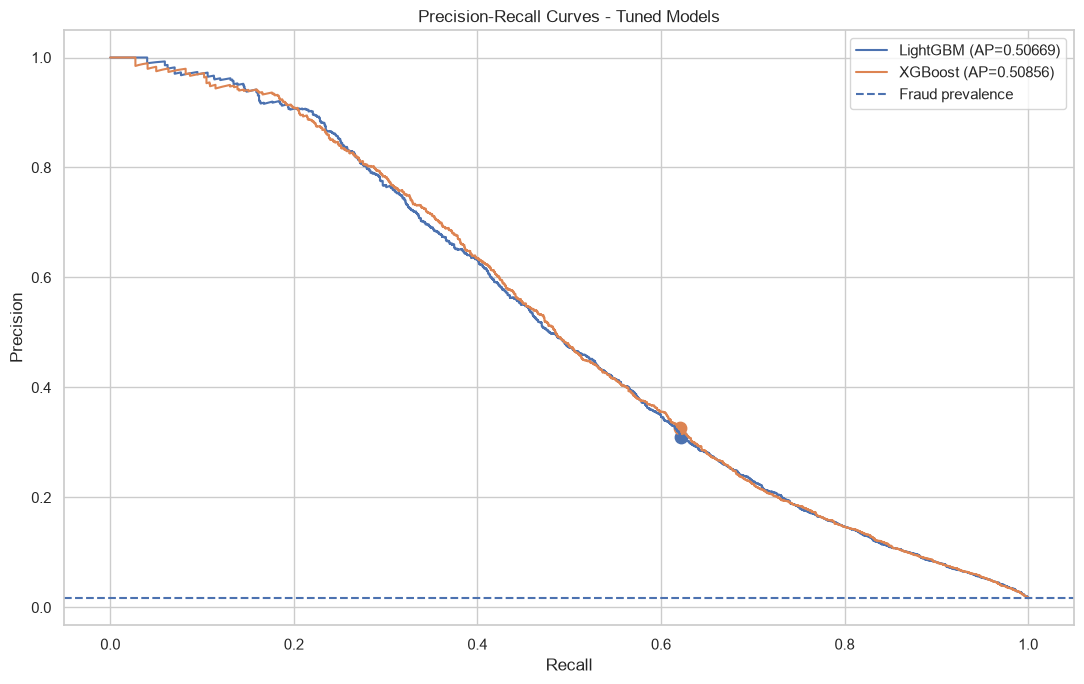

In [21]:
plt.figure(figsize=(11, 7))

for model_name, y_proba in validation_probabilities.items():

    precision_values, recall_values, _ = (
        precision_recall_curve(
            y_valid,
            y_proba
        )
    )

    ap = average_precision_score(
        y_valid,
        y_proba
    )

    plt.plot(
        recall_values,
        precision_values,
        label=f"{model_name} (AP={ap:.5f})"
    )

    # Mark the selected F2 threshold
    threshold = thresholds_by_model[
        model_name
    ]["max_f2"]

    y_pred = (
        y_proba >= threshold
    ).astype("int8")

    selected_precision = precision_score(
        y_valid,
        y_pred,
        zero_division=0
    )

    selected_recall = recall_score(
        y_valid,
        y_pred,
        zero_division=0
    )

    plt.scatter(
        selected_recall,
        selected_precision,
        s=80,
        marker="o"
    )

plt.axhline(
    y=y_valid.mean(),
    linestyle="--",
    label="Fraud prevalence"
)

plt.title("Precision-Recall Curves - Tuned Models")

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.legend()

plt.tight_layout()
plt.show()

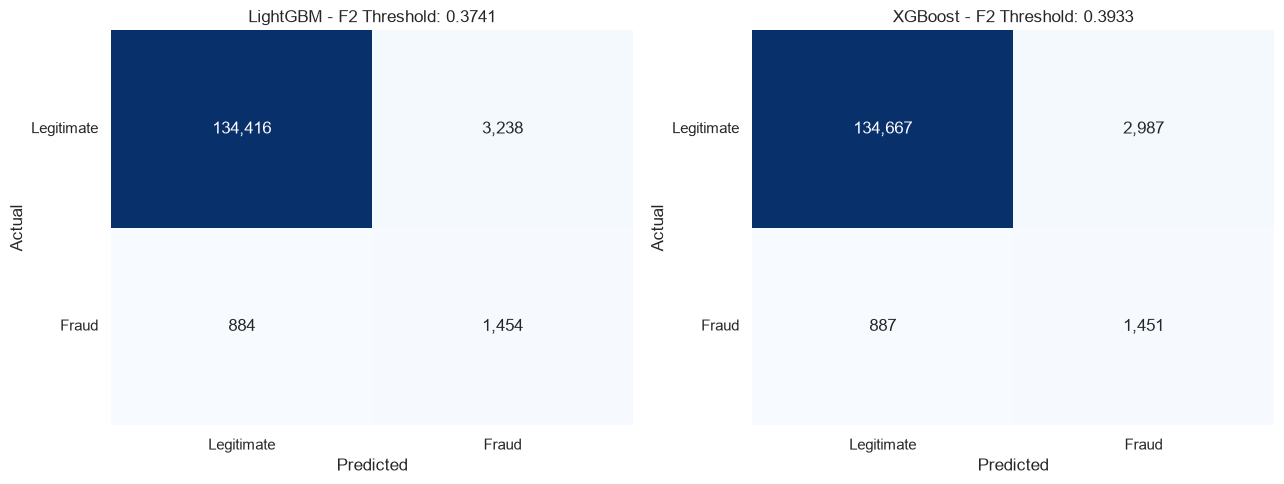

In [22]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

for ax, model_name in zip(
    axes,
    tuned_models.keys()
):

    y_proba = validation_probabilities[
        model_name
    ]

    threshold = thresholds_by_model[
        model_name
    ]["max_f2"]

    y_pred = (
        y_proba >= threshold
    ).astype("int8")

    cm = confusion_matrix(
        y_valid,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt=",",
        cmap="Blues",
        cbar=False,
        ax=ax
    )

    ax.set_title(
        f"{model_name} - F2 Threshold: {threshold:.4f}"
    )

    ax.set_xlabel("Predicted")

    ax.set_ylabel("Actual")

    ax.set_xticklabels(
        ["Legitimate", "Fraud"]
    )

    ax.set_yticklabels(
        ["Legitimate", "Fraud"],
        rotation=0
    )

plt.tight_layout()
plt.show()

# Hyperparameter Tuning - Conclusions

## 1. Cross Validation

- LightGBM baseline CV AP: 0.49043.
- XGBoost baseline CV AP: 0.48336.
- LightGBM tuned CV AP: 0.49588.
- XGBoost tuned CV AP: 0.49813.
- XGBoost achieved the best tuned CV result.
- Both models showed improvements after hyperparameter optimization.

## 2. Hyperparameter Optimization

### LightGBM

- Best CV Average Precision: 0.49588.
- Best CV ROC-AUC: 0.94517.
- n_estimators: 400.
- learning_rate: 0.03.
- num_leaves: 31.
- min_child_samples: 100.
- colsample_bytree: 0.7.

### XGBoost

- Best CV Average Precision: 0.49813.
- Best CV ROC-AUC: 0.94586.
- n_estimators: 300.
- learning_rate: 0.07.
- max_depth: 3.
- min_child_weight: 1.
- subsample: 0.7.
- colsample_bytree: 0.9.
- gamma: 0.1.

## 3. Threshold Optimization

- LightGBM F1 threshold: 0.65282.
- LightGBM F2 threshold: 0.37407.
- XGBoost F1 threshold: 0.68003.
- XGBoost F2 threshold: 0.39327.

F2 optimization prioritized fraud detection and achieved
approximately 62% Recall on external validation.

F1 optimization provided a more balanced Precision-Recall trade-off.

## 4. Validation Performance

- Best validation ROC-AUC: LightGBM (0.94365).
- Best validation Average Precision: XGBoost (0.50856).
- Best validation F1: LightGBM with F1 threshold (0.49662).
- Best Recall: LightGBM with F2 threshold (62.19%).

## 5. Model Selection

Both LightGBM and XGBoost remain final candidates.

XGBoost is the provisional primary candidate due to its
better Cross Validation performance and slightly higher
validation Average Precision.

LightGBM remains competitive and achieved a slightly higher
ROC-AUC on external validation.

## 6. Limitations

- Hyperparameter search was limited to eight configurations
  per model.
- Three-fold cross-validation was used.
- Probability calibration has not been fully investigated.
- The external validation set was used in previous phases.
- The availability of `is_ai_generated_scam_attempt`
  still requires verification.

## 7. Next Steps

- Final model training using all labeled data.
- Generate test probabilities.
- Create Kaggle submission files.
- Evaluate leaderboard performance.
- Complete project documentation.